# Pathology-Based Disease Prediction



## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.multioutput import MultiOutputClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix,accuracy_score, precision_score, recall_score, f1_score
print(" All libraries imported successfully!")

 All libraries imported successfully!


## Step 2: Load Dataset

In [2]:
df = pd.read_csv("pathology_dataset.csv")
df.head()

,Date,Name,Years,Sex,Blood Group,Hemoglobin (Hb %),RBS (mmol/L),Creatinine (mg/dc),ESR(mm/hr),HBsAg,WBC (White Blood Cell),Diseases
0,01/01/2025,Md Altab Hossain,40,Male,O+,11.5,5.7,0.98,48.0,Negative,5400,"Anemia, Inflammation"
1,01/01/2025,Abul Hossain,55,Male,A+,11.5,7.5,0.98,48.0,Negative,10500,"Anemia, Inflammation"
2,01/01/2025,Sathy,55,Female,B+,11.5,25.4,0.69,55.0,Negative,4300,"Anemia, Diabetes, Inflammation"
3,01/01/2025,Ruma Khatun,28,Female,O+,11.5,5.6,0.90,4.0,Negative,7500,Anemia
4,01/01/2025,Salma Khatun,48,Female,AB+,10.6,4.3,0.83,7.3,Negative,7100,Anemia


In [3]:
df.shape

(1210, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1210 entries, 0 to 1209
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Date                    1210 non-null   object 
 1   Name                    1210 non-null   object 
 2   Years                   1210 non-null   int64  
 3   Sex                     1210 non-null   object 
 4   Blood Group             931 non-null    object 
 5   Hemoglobin (Hb %)       1210 non-null   float64
 6   RBS (mmol/L)            1210 non-null   float64
 7   Creatinine (mg/dc)      1210 non-null   float64
 8   ESR(mm/hr)              1210 non-null   float64
 9   HBsAg                   1210 non-null   object 
 10  WBC (White Blood Cell)  1210 non-null   int64  
 11  Diseases                1210 non-null   object 
dtypes: float64(4), int64(2), object(6)
memory usage: 113.6+ KB


In [5]:
df.describe()

,Years,Hemoglobin (Hb %),RBS (mmol/L),Creatinine (mg/dc),ESR(mm/hr),WBC (White Blood Cell)
count,1210.000000,1210.000000,1210.000000,1210.000000,1210.000000,1210.000000
mean,35.325620,11.550165,6.549174,0.877347,28.580826,8937.851240
std,17.265352,2.040902,2.555483,0.183061,22.178881,2050.549446
min,3.000000,5.700000,2.400000,0.350000,1.000000,1700.000000
25%,22.000000,10.000000,5.400000,0.760000,9.800000,7700.000000
50%,30.000000,11.300000,6.000000,0.865000,22.000000,9500.000000
75%,46.000000,12.900000,6.900000,0.990000,45.000000,10500.000000
max,100.000000,17.000000,26.000000,2.750000,110.000000,14900.000000


In [6]:
df.columns

Index(['Date', 'Name', 'Years', 'Sex', 'Blood Group', 'Hemoglobin (Hb %)',
       'RBS (mmol/L)', 'Creatinine (mg/dc)', 'ESR(mm/hr)', 'HBsAg',
       'WBC (White Blood Cell)', 'Diseases'],
      dtype='object')

##  Step 3: Handle Missing Values

In [7]:
df.isnull().sum()

Date                        0
Name                        0
Years                       0
Sex                         0
Blood Group               279
Hemoglobin (Hb %)           0
RBS (mmol/L)                0
Creatinine (mg/dc)          0
ESR(mm/hr)                  0
HBsAg                       0
WBC (White Blood Cell)      0
Diseases                    0
dtype: int64

## Step 4: Exploratory Data Analysis (EDA)

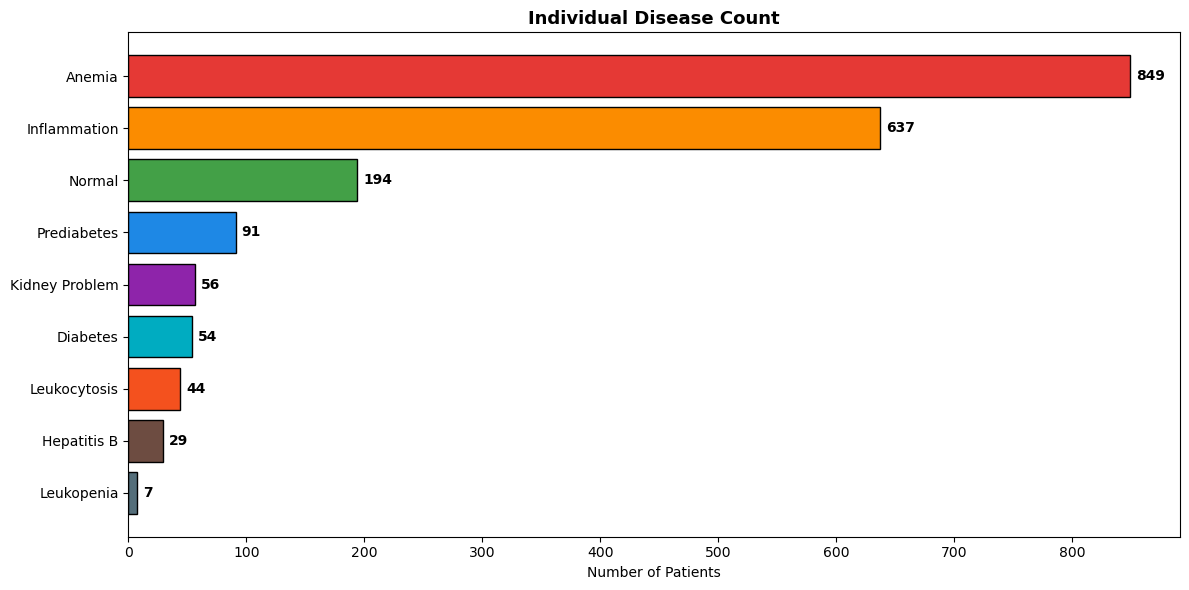

In [8]:
# Disease Distribution
from collections import Counter

all_diseases = []

for d in df['Diseases']:
    for item in d.split(', '):
        all_diseases.append(item.strip())

# Count diseases
disease_counts = Counter(all_diseases)
disease_df = pd.DataFrame(disease_counts.most_common(),columns=['Disease', 'Count'])

fig, ax = plt.subplots(figsize=(12, 6))

# Bar Chart — Individual diseases
colors = ['#E53935', '#FB8C00', '#43A047','#1E88E5', '#8E24AA', '#00ACC1','#F4511E', '#6D4C41', '#546E7A']
bars = ax.barh(disease_df['Disease'],disease_df['Count'],color=colors[:len(disease_df)],edgecolor='black')
ax.set_title('Individual Disease Count',fontsize=13,fontweight='bold')
ax.set_xlabel('Number of Patients')

# Show count beside bars
for bar, val in zip(bars, disease_df['Count']):
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va='center',
        fontweight='bold'
    )

ax.invert_yaxis()
plt.tight_layout()

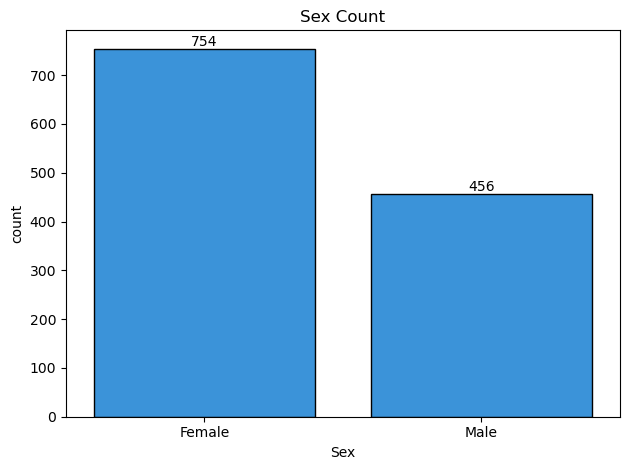

In [32]:
# Categorical Feature Analysis

Sex_cnt=df["Sex"].value_counts()
ax=sns.barplot(Sex_cnt,color='#2196F3', edgecolor='black')
ax.bar_label(ax.containers[0])
plt.title("Sex Count")

plt.tight_layout()

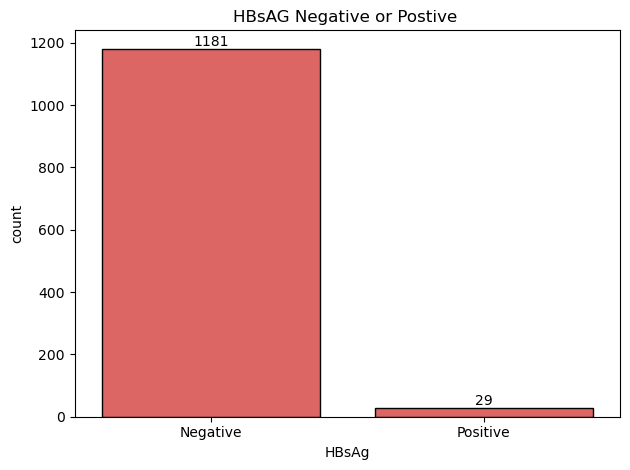

In [34]:
HBsAg_cnt=df["HBsAg"].value_counts()
ax=sns.barplot(HBsAg_cnt,color="#EF5350",edgecolor='black')
ax.bar_label(ax.containers[0])
plt.title("HBsAG Negative or Postive ")
plt.tight_layout()

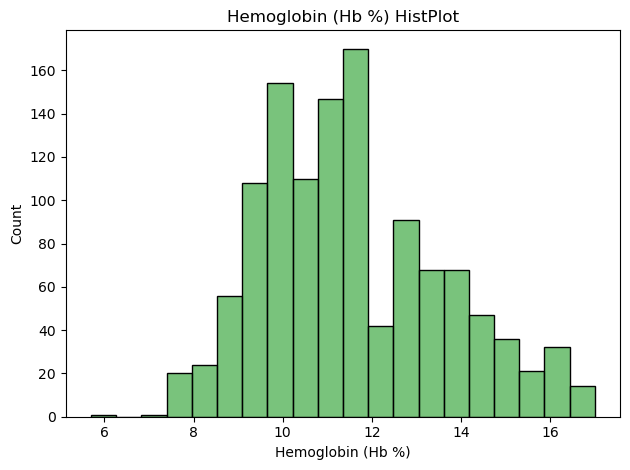

In [11]:
# Numerical Feature Distributions
sns.histplot(
    data=df,
    x="Hemoglobin (Hb %)",
    color="#4CAF50",
    bins=20
)
plt.title("Hemoglobin (Hb %) HistPlot")
plt.tight_layout()

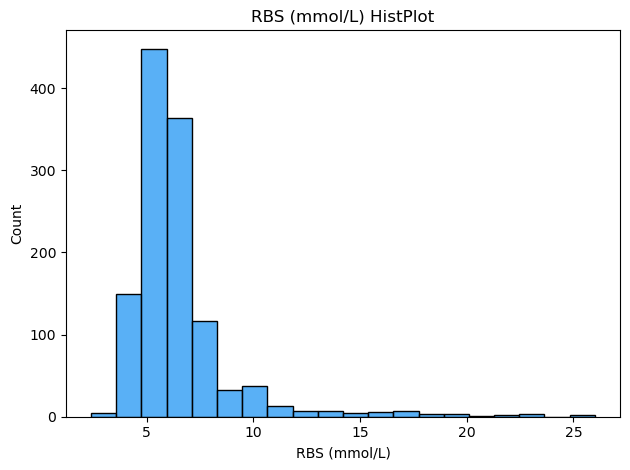

In [12]:
sns.histplot(
    data=df,
    x="RBS (mmol/L)",
    color="#2196F3",
    bins=20
)
plt.title("RBS (mmol/L) HistPlot")
plt.tight_layout()

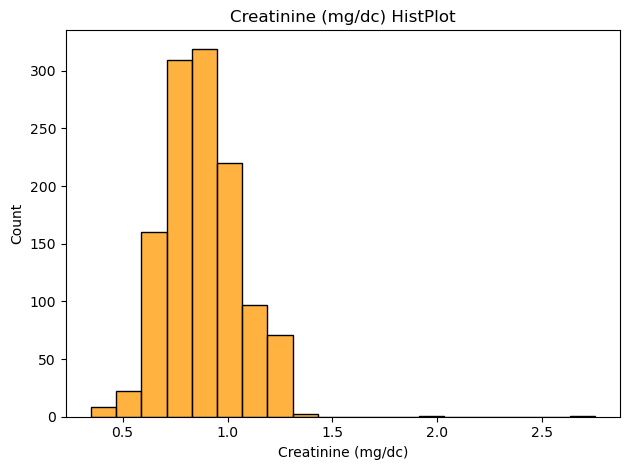

In [13]:
sns.histplot(
    data=df,
    x="Creatinine (mg/dc)",
    color="#FF9800",
    bins=20
)
plt.title("Creatinine (mg/dc) HistPlot")
plt.tight_layout()

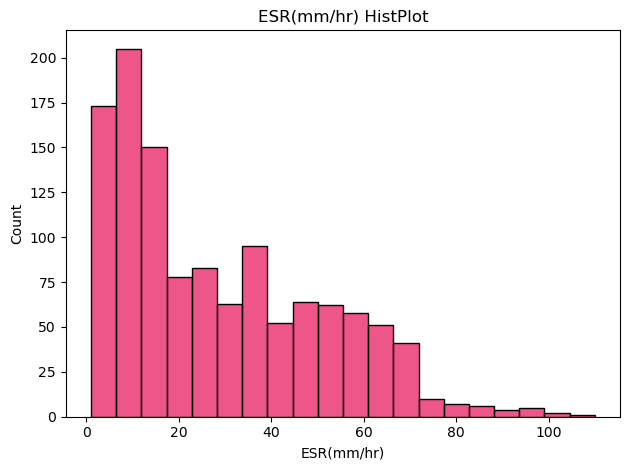

In [14]:
sns.histplot(
    data=df,
    x="ESR(mm/hr)",
    color="#E91E63",
    bins=20
)
plt.title("ESR(mm/hr) HistPlot")
plt.tight_layout()

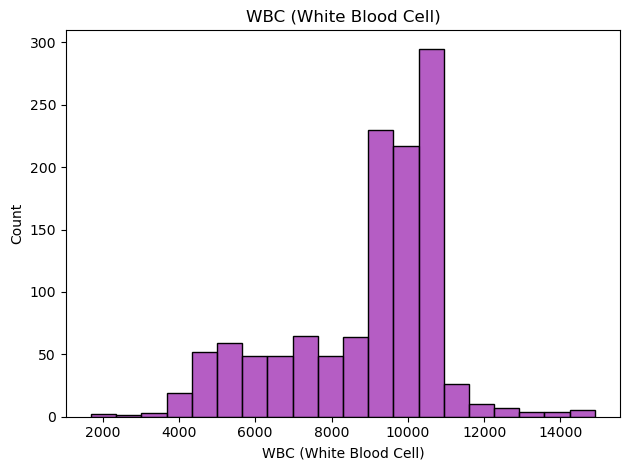

In [15]:
sns.histplot(
    data=df,
    x="WBC (White Blood Cell)",
    color="#9C27B0",
    bins=20
)
plt.title("WBC (White Blood Cell)")
plt.tight_layout()

## Step 5: Preprocessing — Multi-Label Setup

In [16]:
# Drop non-feature columns
df_model = df.drop(columns=['Date', 'Name', 'Years', 'Blood Group'], errors='ignore')

# Encode Sex & HBsAg
le = LabelEncoder()
df_model['Sex']   = le.fit_transform(df_model['Sex'])
df_model['HBsAg'] = df_model['HBsAg'].map({'Negative': 0, 'Positive': 1})
df_model.head()

,Sex,Hemoglobin (Hb %),RBS (mmol/L),Creatinine (mg/dc),ESR(mm/hr),HBsAg,WBC (White Blood Cell),Diseases
0,1,11.5,5.7,0.98,48.0,0,5400,"Anemia, Inflammation"
1,1,11.5,7.5,0.98,48.0,0,10500,"Anemia, Inflammation"
2,0,11.5,25.4,0.69,55.0,0,4300,"Anemia, Diabetes, Inflammation"
3,0,11.5,5.6,0.90,4.0,0,7500,Anemia
4,0,10.6,4.3,0.83,7.3,0,7100,Anemia


In [17]:
# Create binary column for each disease (Multi-Label)
DISEASE_LABELS = [
    'Anemia', 'Prediabetes', 'Diabetes',
    'Kidney Problem', 'Inflammation',
    'Hepatitis B', 'Leukopenia', 'Leukocytosis'
]

for disease in DISEASE_LABELS:
    df_model[disease] = df_model['Diseases'].apply(
        lambda x: 1 if disease in str(x) else 0
    )


df_model.drop(columns=['Diseases'], inplace=True)

In [18]:
df_model.head()

,Sex,Hemoglobin (Hb %),RBS (mmol/L),Creatinine (mg/dc),ESR(mm/hr),HBsAg,WBC (White Blood Cell),Anemia,Prediabetes,Diabetes,Kidney Problem,Inflammation,Hepatitis B,Leukopenia,Leukocytosis
0,1,11.5,5.7,0.98,48.0,0,5400,1,0,0,0,1,0,0,0
1,1,11.5,7.5,0.98,48.0,0,10500,1,0,0,0,1,0,0,0
2,0,11.5,25.4,0.69,55.0,0,4300,1,0,1,0,1,0,0,0
3,0,11.5,5.6,0.90,4.0,0,7500,1,0,0,0,0,0,0,0
4,0,10.6,4.3,0.83,7.3,0,7100,1,0,0,0,0,0,0,0


## Step 6: Correlation Heatmap

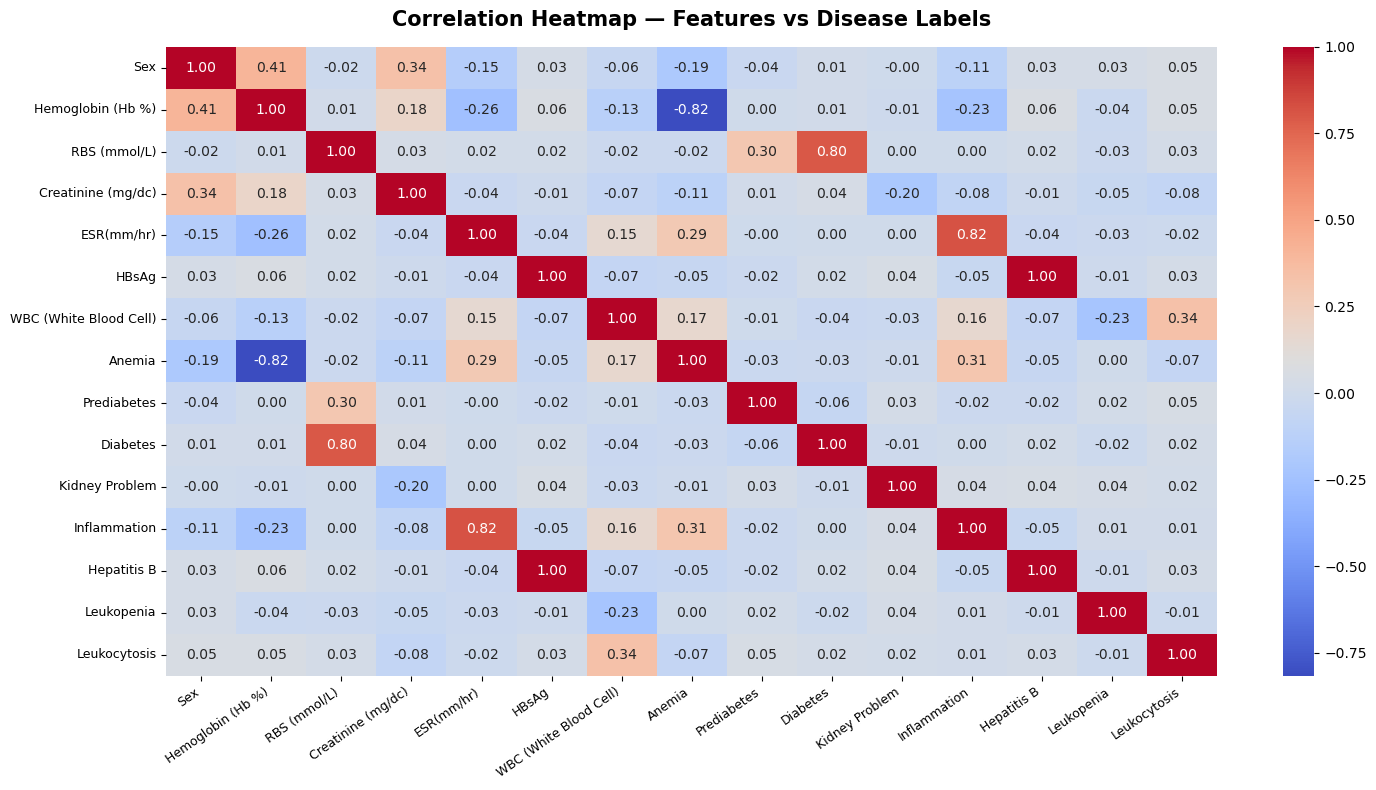

In [19]:
# Correlation Heatmap
nums_cols=df_model.select_dtypes(include=["number"])

corr_matix=nums_cols.corr()

plt.figure(figsize=(15,8))

sns.heatmap(
    corr_matix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title('Correlation Heatmap — Features vs Disease Labels', fontsize=15, fontweight='bold', pad=15)
plt.xticks(rotation=35, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()

## Step 7: Train-Test Split

In [20]:
FEATURES = ['Sex', 'Hemoglobin (Hb %)', 'RBS (mmol/L)',
           'Creatinine (mg/dc)', 'ESR(mm/hr)', 'HBsAg', 'WBC (White Blood Cell)']

X = df_model[FEATURES]
y= df_model[DISEASE_LABELS]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [21]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

## Step 8: Model Training — 5 Models

In [22]:
# Logistic Regression
from sklearn.multioutput import MultiOutputClassifier

log_model = MultiOutputClassifier(LogisticRegression())
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)

print("----------- Logistic Regression Model ---------------")
print("Accuracy  =", accuracy_score(y_test, y_pred_log))
print("Precision =", precision_score(y_test, y_pred_log, average="weighted", zero_division=0))
print("Recall    =", recall_score(y_test, y_pred_log, average="weighted", zero_division=0))
print("F1 Score  =", f1_score(y_test, y_pred_log, average="weighted", zero_division=0))

----------- Logistic Regression Model ---------------
Accuracy  = 0.8636363636363636
Precision = 0.9292709650231773
Recall    = 0.9085545722713865
F1 Score  = 0.9174661532898083


In [23]:
# KNN

knn_model = MultiOutputClassifier(KNeighborsClassifier(n_neighbors=5))
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

print("----------- KNN Model ---------------")
print("Accuracy  =", accuracy_score(y_test, y_pred_knn))
print("Precision =", precision_score(y_test, y_pred_knn, average="weighted", zero_division=0))
print("Recall    =", recall_score(y_test, y_pred_knn, average="weighted", zero_division=0))
print("F1 Score  =", f1_score(y_test, y_pred_knn, average="weighted", zero_division=0))

----------- KNN Model ---------------
Accuracy  = 0.8553719008264463
Precision = 0.9624986302307305
Recall    = 0.887905604719764
F1 Score  = 0.9065283991795007


In [24]:
# Naive Bayes

nb_model = MultiOutputClassifier(GaussianNB())
nb_model.fit(X_train_scaled, y_train)
y_pred_nb = nb_model.predict(X_test_scaled)

print("----------- Naive Bayes Model ---------------")
print("Accuracy  =", accuracy_score(y_test, y_pred_nb))
print("Precision =", precision_score(y_test, y_pred_nb, average="weighted", zero_division=0))
print("Recall    =", recall_score(y_test, y_pred_nb, average="weighted", zero_division=0))
print("F1 Score  =", f1_score(y_test, y_pred_nb, average="weighted", zero_division=0))

----------- Naive Bayes Model ---------------
Accuracy  = 0.7355371900826446
Precision = 0.8767966081982639
Recall    = 0.9056047197640118
F1 Score  = 0.8742485471829909


In [25]:
# Decision Tree

dt_model = MultiOutputClassifier(DecisionTreeClassifier(max_depth=3,min_samples_leaf=15,random_state=42))
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)

print("----------- Decision Tree Model ---------------")
print("Accuracy  =", accuracy_score(y_test, y_pred_dt))
print("Precision =", precision_score(y_test, y_pred_dt, average="weighted", zero_division=0))
print("Recall    =", recall_score(y_test, y_pred_dt, average="weighted", zero_division=0))
print("F1 Score  =", f1_score(y_test, y_pred_dt, average="weighted", zero_division=0))

----------- Decision Tree Model ---------------
Accuracy  = 0.9710743801652892
Precision = 0.9940511307767945
Recall    = 0.9793510324483776
F1 Score  = 0.9856558030331162


In [26]:
# SVM Classification

svm_model = MultiOutputClassifier(SVC(random_state=42))
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

print("----------- SVM Classification Model ---------------")

print("Accuracy  =", accuracy_score(y_test, y_pred_svm))
print("Precision =", precision_score(y_test,y_pred_svm,average="weighted",zero_division=0))
print("Recall    =", recall_score(y_test,y_pred_svm,average="weighted",zero_division=0))
print("F1 Score  =", f1_score(y_test,y_pred_svm,average="weighted",zero_division=0))

----------- SVM Classification Model ---------------
Accuracy  = 0.9008264462809917
Precision = 0.9860221069406301
Recall    = 0.9233038348082596
F1 Score  = 0.9402512085764234


## Step 9: Model Performance Summary Table

In [39]:
# Model Performance Summary

results = {
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_log, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_log, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_log, average="weighted", zero_division=0)
    ],

    "KNN": [
        accuracy_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_knn, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_knn, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_knn, average="weighted", zero_division=0)
    ],

    "Naive Bayes": [
        accuracy_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_nb, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_nb, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],

    "Decision Tree": [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_dt, average="weighted", zero_division=0)
    ],

    "SVM": [
        accuracy_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_svm, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_svm, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_svm, average="weighted", zero_division=0)
    ]
}

# Create DataFrame
summary_df = pd.DataFrame(
    results,
    index=["Accuracy", "Precision", "Recall", "F1 Score"]
).T

# Convert to percentage
summary_df = (summary_df * 100).round(2)
summary_df

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,86.36,92.93,90.86,91.75
KNN,85.54,96.25,88.79,90.65
Naive Bayes,73.55,87.68,90.56,87.42
Decision Tree,97.11,99.41,97.94,98.57
SVM,90.08,98.60,92.33,94.03


# Best Model

In [40]:

best_model = summary_df["F1 Score"].idxmax()
best_score = summary_df.loc[best_model, "F1 Score"]

print("Best Model:", best_model)
print("F1 Score:", best_score, "%")

Best Model: Decision Tree
F1 Score: 98.57 %
